# Why a Single Validation Split Can Be Misleading — and Why We Use K-Fold Cross-Validation

Today's goal is to understand the difference between:

$$
\boxed{\text{training error}}
\qquad
\boxed{\text{validation error}}
\qquad
\boxed{\text{test error}}
$$

and to see why a **single validation split** can give a noisy or unstable estimate of model quality.

We will use polynomial regression as a simple model-selection problem:

$$
\hat y(x)
=
\theta_0+\theta_1x+\cdots+\theta_dx^d.
$$

The polynomial degree \(d\) is a **hyperparameter**.

We will compare:

1. one train/validation split;
2. many different random train/validation splits;
3. \(K\)-fold cross-validation;
4. final evaluation on an untouched test set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)

## 1. Generate one dataset

We use a smooth nonlinear relationship,

\[
Y=f(X)+\varepsilon,
\]

with Gaussian noise.

The point is not the particular function; the point is to study **model selection**.

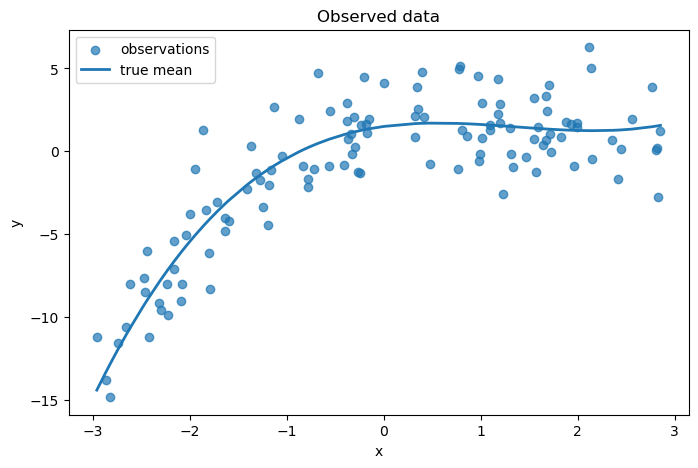

In [2]:
n = 120
x = np.sort(rng.uniform(-3, 3, n))

def f_true(x):
    return 1.5 + 0.8*x - 0.9*x**2 + 0.22*x**3

y_true = f_true(x)
y = y_true + rng.normal(0, 2.0, n)

plt.figure(figsize=(8,5))
plt.scatter(x, y, alpha=0.7, label="observations")
plt.plot(x, y_true, linewidth=2, label="true mean")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Observed data")
plt.legend()
plt.show()

## 2. Keep a final test set untouched

Before doing any model selection, we reserve a test set.

This set will **not** be used to choose the polynomial degree.

$$
\boxed{
\text{test set}
=
\text{final estimate of generalization error}
}
$$

In [5]:
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=1
)

print("Train/validation pool:", len(x_trainval))
print("Test set:", len(x_test))

Train/validation pool: 96
Test set: 24


# Part I: A single validation split

Split the remaining data once:

$$
\text{training set}
\quad+\quad
\text{validation set}.
$$

For each degree \(d\),

1. fit the model on the training set;
2. compute validation MSE;
3. choose the degree with smallest validation MSE.

In [6]:
x_tr, x_val, y_tr, y_val = train_test_split(
    x_trainval, y_trainval,
    test_size=0.25,
    random_state=2
)

degrees = np.arange(1, 16)

train_mse = []
val_mse = []

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)

    Xtr = poly.fit_transform(x_tr.reshape(-1,1))
    Xval = poly.transform(x_val.reshape(-1,1))

    model = LinearRegression()
    model.fit(Xtr, y_tr)

    train_mse.append(mean_squared_error(y_tr, model.predict(Xtr)))
    val_mse.append(mean_squared_error(y_val, model.predict(Xval)))

best_degree_single = degrees[np.argmin(val_mse)]

print("Best degree from this one split:", best_degree_single)

Best degree from this one split: 3


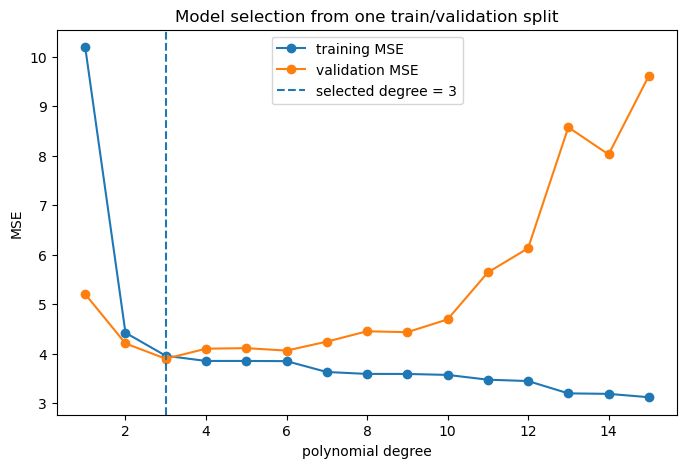

In [7]:
plt.figure(figsize=(8,5))
plt.plot(degrees, train_mse, marker="o", label="training MSE")
plt.plot(degrees, val_mse, marker="o", label="validation MSE")
plt.axvline(best_degree_single, linestyle="--", label=f"selected degree = {best_degree_single}")
plt.xlabel("polynomial degree")
plt.ylabel("MSE")
plt.title("Model selection from one train/validation split")
plt.legend()
plt.show()

The training error typically decreases as model complexity increases.

But the validation curve depends on **which observations happened to land in the validation set**.

This is the main weakness of a single split.

## 3. Repeat the single split many times

Now repeat exactly the same procedure with many different random train/validation splits.

If the single-split procedure were very stable, we would choose roughly the same degree every time.

In [8]:
selected_degrees = []
all_val_curves = []

for seed in range(80):
    x_tr, x_val, y_tr, y_val = train_test_split(
        x_trainval, y_trainval,
        test_size=0.25,
        random_state=seed
    )

    curve = []

    for d in degrees:
        poly = PolynomialFeatures(degree=d, include_bias=False)

        Xtr = poly.fit_transform(x_tr.reshape(-1,1))
        Xval = poly.transform(x_val.reshape(-1,1))

        model = LinearRegression()
        model.fit(Xtr, y_tr)

        curve.append(mean_squared_error(y_val, model.predict(Xval)))

    all_val_curves.append(curve)
    selected_degrees.append(degrees[np.argmin(curve)])

all_val_curves = np.array(all_val_curves)
selected_degrees = np.array(selected_degrees)

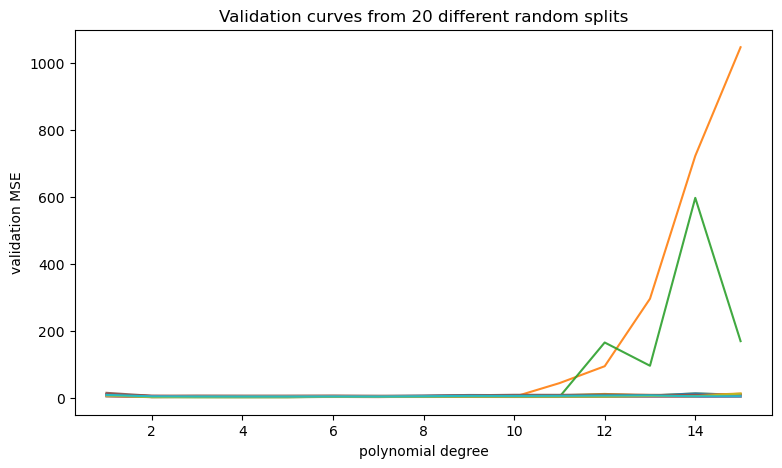

In [9]:
plt.figure(figsize=(9,5))

for i in range(20):
    plt.plot(degrees, all_val_curves[i], alpha=0.9)

plt.xlabel("polynomial degree")
plt.ylabel("validation MSE")
plt.title("Validation curves from 20 different random splits")
plt.show()

The curves can move substantially from split to split.

That means the selected model can depend on the luck of the split.

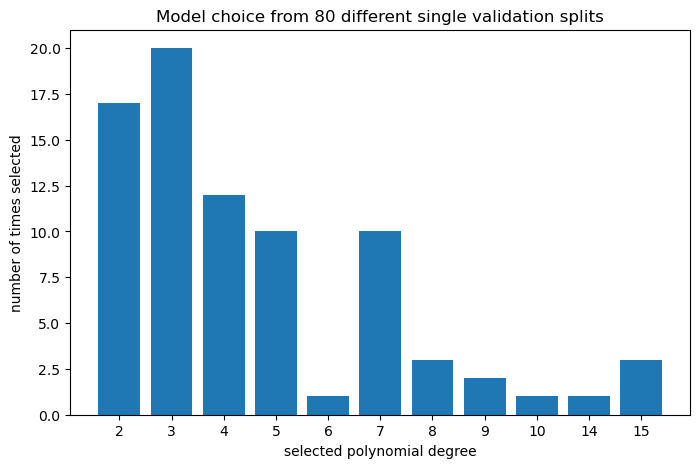

2     17
3     20
4     12
5     10
6      1
7     10
8      3
9      2
10     1
14     1
15     3
Name: count, dtype: int64

In [10]:
counts = pd.Series(selected_degrees).value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel("selected polynomial degree")
plt.ylabel("number of times selected")
plt.title("Model choice from 80 different single validation splits")
plt.show()

counts

This is the key drawback of a single validation split:

$$
\boxed{
\text{model choice can have high variance}.
}
$$

A small validation set may not be representative of the population.

One split may make a model look very good; another may make the same model look poor.

# Part II: K-fold cross-validation

Instead of using one fixed validation subset, divide the training data into \(K\) folds:

$$
D_1,\ldots,D_K.
$$

For fold \(k\):

- train on the other \(K-1\) folds;
- validate on \(D_k\).

Every observation serves as validation data exactly once.

For model complexity \(d\),

$$
\boxed{
CV_K(d)
=
\frac{1}{K}
\sum_{k=1}^K
MSE_k(d).
}
$$

In [11]:
K = 5
kf = KFold(n_splits=K, shuffle=True, random_state=10)

cv_mean = []
cv_sd = []

for d in degrees:
    fold_errors = []

    for train_idx, val_idx in kf.split(x_trainval):
        x_tr = x_trainval[train_idx]
        y_tr = y_trainval[train_idx]

        x_val = x_trainval[val_idx]
        y_val = y_trainval[val_idx]

        poly = PolynomialFeatures(degree=d, include_bias=False)

        Xtr = poly.fit_transform(x_tr.reshape(-1,1))
        Xval = poly.transform(x_val.reshape(-1,1))

        model = LinearRegression()
        model.fit(Xtr, y_tr)

        fold_errors.append(
            mean_squared_error(y_val, model.predict(Xval))
        )

    cv_mean.append(np.mean(fold_errors))
    cv_sd.append(np.std(fold_errors))

cv_mean = np.array(cv_mean)
cv_sd = np.array(cv_sd)

best_degree_cv = degrees[np.argmin(cv_mean)]

print("Degree selected by 5-fold CV:", best_degree_cv)

Degree selected by 5-fold CV: 3


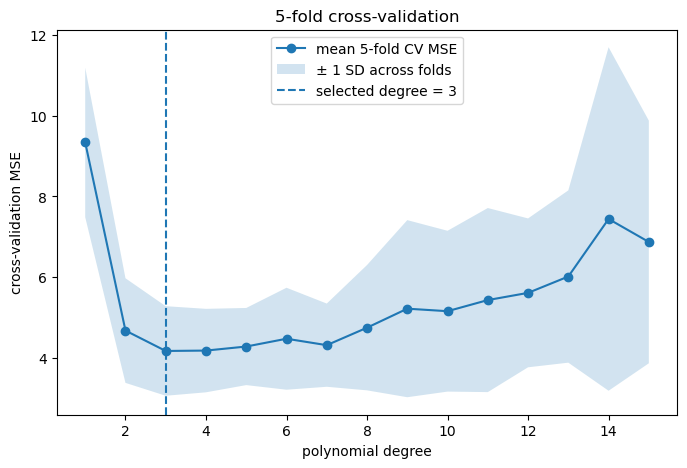

In [12]:
plt.figure(figsize=(8,5))
plt.plot(degrees, cv_mean, marker="o", label="mean 5-fold CV MSE")
plt.fill_between(
    degrees,
    cv_mean-cv_sd,
    cv_mean+cv_sd,
    alpha=0.2,
    label="± 1 SD across folds"
)
plt.axvline(best_degree_cv, linestyle="--", label=f"selected degree = {best_degree_cv}")
plt.xlabel("polynomial degree")
plt.ylabel("cross-validation MSE")
plt.title("5-fold cross-validation")
plt.legend()
plt.show()

Compared with one arbitrary split, cross-validation averages over several validation sets.

So it tends to give a more stable estimate of out-of-sample error.

It does **not** make the estimate noise-free, but it usually reduces dependence on one lucky or unlucky split.

## 4. Compare single-split variability with K-fold CV variability

Now repeat the entire 5-fold CV procedure with different fold assignments.

In [13]:
selected_cv_degrees = []

for seed in range(40):
    kf = KFold(n_splits=5, shuffle=True, random_state=seed)

    mean_curve = []

    for d in degrees:
        errors = []

        for tr_idx, va_idx in kf.split(x_trainval):
            x_tr = x_trainval[tr_idx]
            y_tr = y_trainval[tr_idx]
            x_va = x_trainval[va_idx]
            y_va = y_trainval[va_idx]

            poly = PolynomialFeatures(degree=d, include_bias=False)
            Xtr = poly.fit_transform(x_tr.reshape(-1,1))
            Xva = poly.transform(x_va.reshape(-1,1))

            model = LinearRegression()
            model.fit(Xtr, y_tr)

            errors.append(
                mean_squared_error(y_va, model.predict(Xva))
            )

        mean_curve.append(np.mean(errors))

    selected_cv_degrees.append(
        degrees[np.argmin(mean_curve)]
    )

selected_cv_degrees = np.array(selected_cv_degrees)

In [14]:
single_counts = pd.Series(selected_degrees).value_counts().sort_index()
cv_counts = pd.Series(selected_cv_degrees).value_counts().sort_index()

all_degrees = sorted(set(single_counts.index).union(cv_counts.index))

comparison = pd.DataFrame({
    "degree": all_degrees,
    "single_split_count": [single_counts.get(d,0) for d in all_degrees],
    "five_fold_cv_count": [cv_counts.get(d,0) for d in all_degrees]
})

comparison

,degree,single_split_count,five_fold_cv_count
0,2,17,0
1,3,20,29
2,4,12,10
3,5,10,0
4,6,1,0
5,7,10,1
6,8,3,0
7,9,2,0
8,10,1,0
9,14,1,0


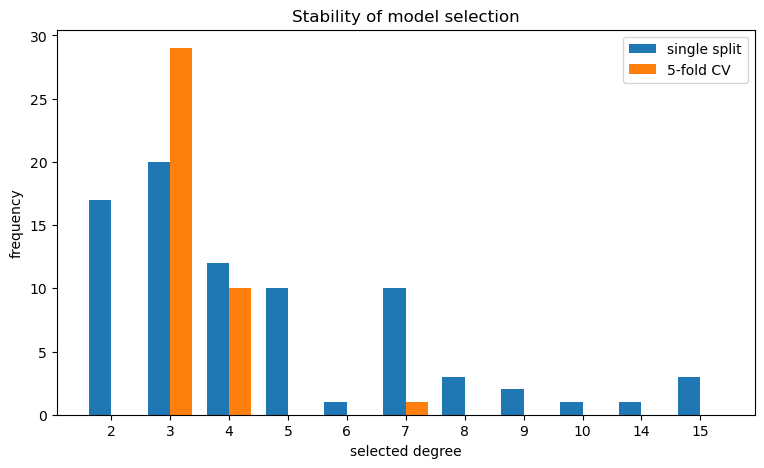

In [15]:
plt.figure(figsize=(9,5))

w = 0.38
pos = np.arange(len(all_degrees))

plt.bar(pos-w/2, comparison["single_split_count"], width=w, label="single split")
plt.bar(pos+w/2, comparison["five_fold_cv_count"], width=w, label="5-fold CV")

plt.xticks(pos, all_degrees)
plt.xlabel("selected degree")
plt.ylabel("frequency")
plt.title("Stability of model selection")
plt.legend()
plt.show()

The precise result depends on the random dataset, but the general lesson is:

$$
\boxed{
\text{single split}
\Rightarrow
\text{selection depends strongly on one partition}
}
$$

whereas

$$
\boxed{
K\text{-fold CV}
\Rightarrow
\text{average performance over multiple partitions}.
}
$$

# Part III: Final test-set evaluation

After choosing the degree using cross-validation, we fit the selected model using **all training/validation data**.

Only then do we evaluate once on the untouched test set.

In [16]:
poly_final = PolynomialFeatures(
    degree=best_degree_cv,
    include_bias=False
)

X_trainval_final = poly_final.fit_transform(
    x_trainval.reshape(-1,1)
)

X_test_final = poly_final.transform(
    x_test.reshape(-1,1)
)

final_model = LinearRegression()
final_model.fit(X_trainval_final, y_trainval)

test_pred = final_model.predict(X_test_final)

test_mse = mean_squared_error(y_test, test_pred)

print("Selected degree:", best_degree_cv)
print("Final test MSE:", test_mse)

Selected degree: 3
Final test MSE: 4.7313671259901655


This test error is different from validation error.

The validation/CV data were used to choose the model.

The test set was not.

Therefore:

$$
\boxed{
\text{CV error}
=
\text{model selection}
}
$$

$$
\boxed{
\text{test error}
=
\text{final generalization estimate}.
}
$$

# 5. Visualize the final selected model

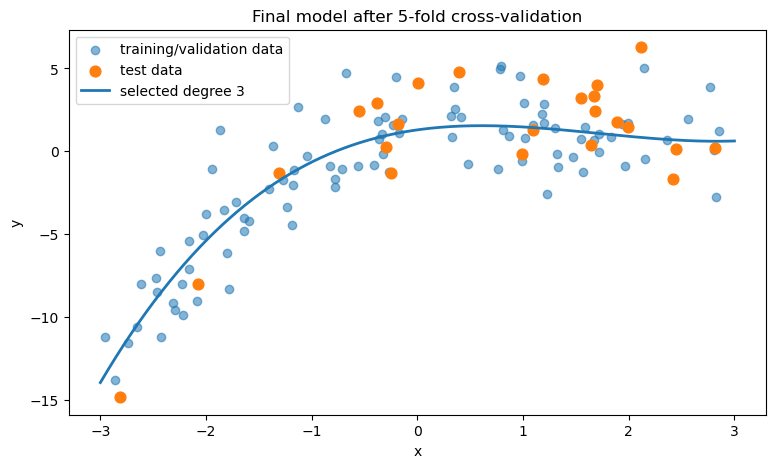

In [17]:
xg = np.linspace(-3,3,500)
Xg = poly_final.transform(xg.reshape(-1,1))
yg = final_model.predict(Xg)

plt.figure(figsize=(9,5))
plt.scatter(x_trainval, y_trainval, alpha=0.55, label="training/validation data")
plt.scatter(x_test, y_test, s=60, label="test data")
plt.plot(xg, yg, linewidth=2, label=f"selected degree {best_degree_cv}")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Final model after 5-fold cross-validation")
plt.legend()
plt.show()

# Take-home message

A single validation split is simple, but it can be unstable:

$$
\boxed{
\text{one split}
\Rightarrow
\text{one noisy estimate of generalization error}.
}
$$

K-fold cross-validation reduces dependence on one arbitrary split:

$$
\boxed{
CV_K
=
\frac1K\sum_{k=1}^{K}MSE_k.
}
$$

A standard workflow is:

$$
\boxed{
\text{training data}
\xrightarrow{K\text{-fold CV}}
\text{choose hyperparameters}
\xrightarrow{\text{refit}}
\text{final model}
\xrightarrow{\text{test set}}
\text{final evaluation}.
}
$$

Cross-validation replaces the **validation split**.

It does **not** replace the final test set.